In [12]:
import pandas as pd
from pathlib import Path

ROOT = Path("..")                      # notebook is in notebooks/, project root is one level up
RAW = ROOT / "data" / "raw"

df = pd.read_csv(RAW / "styles.csv", on_bad_lines="skip")
print(df.shape)
df.head()

(44424, 10)


,id,gender,masterCategory,subCategory,articleType,baseColour,season,year,usage,productDisplayName
0,15970,Men,Apparel,Topwear,Shirts,Navy Blue,Fall,2011.0,Casual,Turtle Check Men Navy Blue Shirt
1,39386,Men,Apparel,Bottomwear,Jeans,Blue,Summer,2012.0,Casual,Peter England Men Party Blue Jeans
2,59263,Women,Accessories,Watches,Watches,Silver,Winter,2016.0,Casual,Titan Women Silver Watch
3,21379,Men,Apparel,Bottomwear,Track Pants,Black,Fall,2011.0,Casual,Manchester United Men Solid Black Track Pants
4,53759,Men,Apparel,Topwear,Tshirts,Grey,Summer,2012.0,Casual,Puma Men Grey T-shirt


In [13]:
df.isna().sum()

id                      0
gender                  0
masterCategory          0
subCategory             0
articleType             0
baseColour             15
season                 21
year                    1
usage                 317
productDisplayName      7
dtype: int64

In [14]:
print(df["masterCategory"].value_counts())

pd.set_option("display.max_rows", 100)
fashion = df[df.masterCategory.isin(["Apparel", "Footwear", "Accessories"])]
fashion["articleType"].value_counts().head(30)

masterCategory
Apparel           21397
Accessories       11274
Footwear           9219
Personal Care      2403
Free Items          105
Sporting Goods       25
Home                  1
Name: count, dtype: int64


articleType
Tshirts         7067
Shirts          3217
Casual Shoes    2845
Watches         2542
Sports Shoes    2036
Kurtas          1844
Tops            1762
Handbags        1757
Heels           1323
Sunglasses      1073
Wallets          935
Flip Flops       914
Sandals          897
Briefs           849
Belts            813
Backpacks        722
Socks            686
Formal Shoes     637
Jeans            609
Shorts           547
Trousers         530
Flats            500
Bra              477
Dresses          464
Sarees           427
Earrings         416
Track Pants      304
Clutches         289
Sweatshirts      285
Caps             283
Name: count, dtype: int64

In [15]:
KEEP = ["Tshirts", "Shirts", "Tops", "Jeans", "Shorts",
        "Casual Shoes", "Sports Shoes", "Heels", "Handbags", "Watches"]

counts = df["articleType"].value_counts()
for k in KEEP:
    print(f"{k:15s} {counts.get(k, 0)}")

Tshirts         7067
Shirts          3217
Tops            1762
Jeans           609
Shorts          547
Casual Shoes    2845
Sports Shoes    2036
Heels           1323
Handbags        1759
Watches         2542


In [16]:
print(df["baseColour"].value_counts().head(10))
print(df["season"].value_counts())
print(df["gender"].value_counts())

baseColour
Black        9728
White        5538
Blue         4918
Brown        3494
Grey         2741
Red          2455
Green        2115
Pink         1860
Navy Blue    1789
Purple       1640
Name: count, dtype: int64
season
Summer    21472
Fall      11431
Winter     8517
Spring     2983
Name: count, dtype: int64
gender
Men       22147
Women     18631
Unisex     2161
Boys        830
Girls       655
Name: count, dtype: int64


In [17]:
missing = [i for i in df.id if not (RAW / "images" / f"{i}.jpg").exists()]
print("rows without an image:", len(missing))

rows without an image: 5


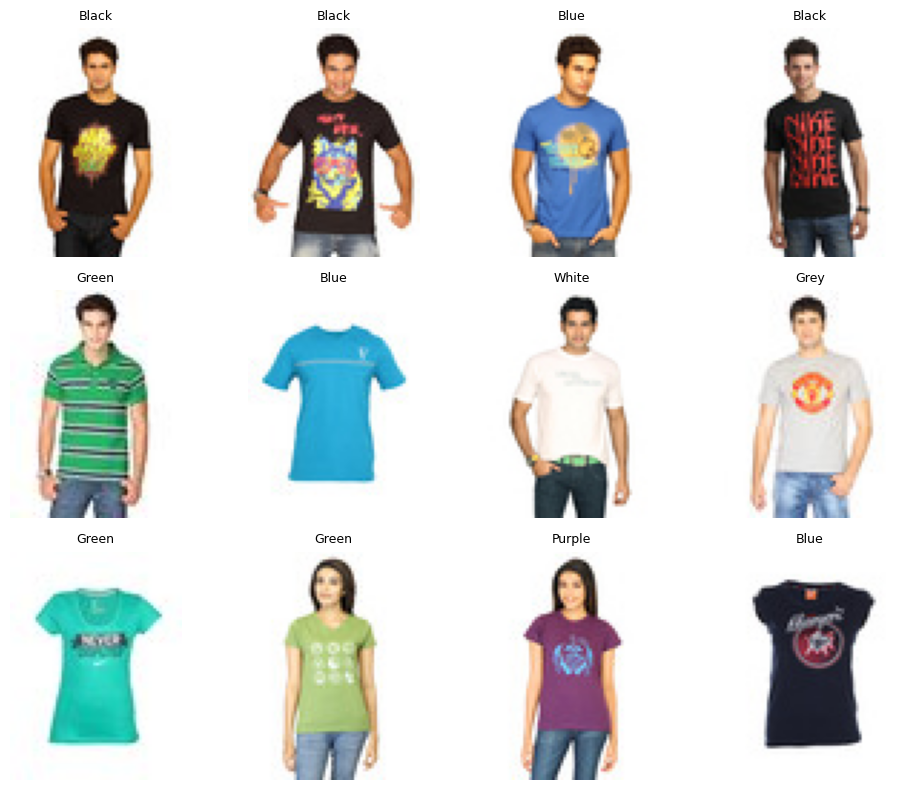

In [18]:
import matplotlib.pyplot as plt
from PIL import Image

sample = df[df.articleType == "Tshirts"].sample(12, random_state=0)

fig, axes = plt.subplots(3, 4, figsize=(10, 8))
for ax, (_, row) in zip(axes.ravel(), sample.iterrows()):
    path = RAW / "images" / f"{row.id}.jpg"
    if path.exists():
        ax.imshow(Image.open(path))
    ax.set_title(row.baseColour, fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()
